In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

project = Path.home() / "deep-learning-project1"
data = project / "data"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA A100-SXM4-40GB


In [8]:
train_df = pd.read_csv(project / "train_labels.csv")
test_df = pd.read_csv(project / "test.csv")

train_paths = {
    p.name: p for p in data.rglob("train_*.png")
}

test_paths = {
    p.name: p for p in data.rglob("test_*.png")
}

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandAugment(num_ops=2, magnitude=7),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    ),
    transforms.RandomErasing(
        p=0.25,
        scale=(0.02, 0.12)
    )
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

print("Training images:", len(train_paths))
print("Test images:", len(test_paths))

assert len(train_paths) == 50000
assert len(test_paths) == 2000

Training images: 50000
Test images: 2000


In [9]:
class CIFARCompetitionDataset(Dataset):
    def __init__(self, dataframe, image_paths, transform=None, labeled=True):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_paths = image_paths
        self.transform = transform
        self.labeled = labeled

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(
            self.image_paths[row["filename"]]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.labeled:
            return image, int(row["label"])

        return image


train_split, val_split = train_test_split(
    train_df,
    test_size=0.1,
    random_state=42,
    stratify=train_df["label"]
)

train_dataset = CIFARCompetitionDataset(
    train_split, train_paths, train_transform
)

val_dataset = CIFARCompetitionDataset(
    val_split, train_paths, test_transform
)

test_dataset = CIFARCompetitionDataset(
    test_df, test_paths, test_transform, labeled=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Training: 45000
Validation: 5000
Test: 2000


In [10]:
class PreActBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.bn1 = nn.BatchNorm2d(in_channels)
        self.relu1 = nn.ReLU(inplace=False)

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu2 = nn.ReLU(inplace=False)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            padding=1, bias=False
        )

        self.shortcut = nn.Identity()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Conv2d(
                in_channels, out_channels, 1,
                stride=stride, bias=False
            )

    def forward(self, x):
        out = self.relu1(self.bn1(x))

        shortcut = self.shortcut(out) if not isinstance(
            self.shortcut, nn.Identity
        ) else x

        out = self.conv1(out)
        out = self.conv2(self.relu2(self.bn2(out)))

        return out + shortcut


class ResNetV3(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.stem = nn.Conv2d(
            3, 48, 3, padding=1, bias=False
        )

        self.layers = nn.Sequential(
            PreActBlock(48, 96),
            PreActBlock(96, 96),
            PreActBlock(96, 96),

            PreActBlock(96, 144, stride=2),
            PreActBlock(144, 144),
            PreActBlock(144, 144),

            PreActBlock(144, 192, stride=2),
            PreActBlock(192, 192),
            PreActBlock(192, 192)
        )

        self.bn = nn.BatchNorm2d(192)
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(192, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        x = self.relu(self.bn(x))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


model = ResNetV3().to(device)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"V3 trainable parameters: {parameters:,}")

assert parameters < 5_000_000

V3 trainable parameters: 3,476,026


In [11]:
def mixup(images, labels, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    indices = torch.randperm(images.size(0), device=images.device)

    mixed = lam * images + (1 - lam) * images[indices]

    return mixed, labels, labels[indices], lam


epochs = 120

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9,
    weight_decay=5e-4,
    nesterov=True
)

warmup = optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=0.1,
    total_iters=5
)

cosine = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs - 5,
    eta_min=0.0001
)

scheduler = optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[warmup, cosine],
    milestones=[5]
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

print("V3 training setup complete.")

V3 training setup complete.


In [12]:
checkpoint_path = project / "checkpoint_v3.pth"
best_model_path = project / "best_resnet_v3.pth"

start_epoch = 0
best_accuracy = 0
train_losses = []
val_accuracies = []

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])

    start_epoch = checkpoint["epoch"]
    best_accuracy = checkpoint["best_accuracy"]
    train_losses = checkpoint["train_losses"]
    val_accuracies = checkpoint["val_accuracies"]

    print("Resuming from epoch:", start_epoch)
    print(f"Best accuracy so far: {best_accuracy:.2f}%")

else:
    print("No V3 checkpoint found. Starting fresh.")


Resuming from epoch: 120
Best accuracy so far: 95.98%


In [7]:
for epoch in range(start_epoch, epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        use_mixup = np.random.rand() < 0.5

        if use_mixup:
            images, labels_a, labels_b, lam = mixup(
                images, labels
            )

        optimizer.zero_grad()

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

            if use_mixup:
                loss = (
                    lam * criterion(outputs, labels_a)
                    + (1 - lam) * criterion(outputs, labels_b)
                )
            else:
                loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

    train_loss = total_loss / len(train_dataset)

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)

            correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            total += labels.size(0)

    val_accuracy = 100 * correct / total

    scheduler.step()

    train_losses.append(train_loss)
    val_accuracies.append(val_accuracy)

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            best_model_path
        )

    torch.save({
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "best_accuracy": best_accuracy,
        "train_losses": train_losses,
        "val_accuracies": val_accuracies
    }, checkpoint_path)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Best: {best_accuracy:.2f}%",
        flush=True
    )

Epoch 1/120 | Loss: 1.7703 | Val Acc: 52.06% | Best: 52.06%
Epoch 2/120 | Loss: 1.4825 | Val Acc: 65.16% | Best: 65.16%
Epoch 3/120 | Loss: 1.3341 | Val Acc: 74.68% | Best: 74.68%
Epoch 4/120 | Loss: 1.2786 | Val Acc: 75.56% | Best: 75.56%


/home/dji9692/.local/lib/python3.9/site-packages/torch/optim/lr_scheduler.py:209: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


Epoch 5/120 | Loss: 1.2034 | Val Acc: 73.18% | Best: 75.56%
Epoch 6/120 | Loss: 1.1890 | Val Acc: 70.30% | Best: 75.56%
Epoch 7/120 | Loss: 1.1523 | Val Acc: 74.56% | Best: 75.56%
Epoch 8/120 | Loss: 1.1183 | Val Acc: 80.56% | Best: 80.56%
Epoch 9/120 | Loss: 1.0976 | Val Acc: 75.26% | Best: 80.56%
Epoch 10/120 | Loss: 1.0971 | Val Acc: 76.80% | Best: 80.56%
Epoch 11/120 | Loss: 1.0796 | Val Acc: 77.56% | Best: 80.56%
Epoch 12/120 | Loss: 1.0714 | Val Acc: 83.04% | Best: 83.04%
Epoch 13/120 | Loss: 1.0771 | Val Acc: 76.28% | Best: 83.04%
Epoch 14/120 | Loss: 1.0661 | Val Acc: 80.78% | Best: 83.04%
Epoch 15/120 | Loss: 1.0769 | Val Acc: 68.84% | Best: 83.04%
Epoch 16/120 | Loss: 1.0376 | Val Acc: 83.70% | Best: 83.70%
Epoch 17/120 | Loss: 1.0134 | Val Acc: 83.70% | Best: 83.70%
Epoch 18/120 | Loss: 1.0257 | Val Acc: 76.38% | Best: 83.70%
Epoch 19/120 | Loss: 1.0092 | Val Acc: 83.48% | Best: 83.70%
Epoch 20/120 | Loss: 1.0272 | Val Acc: 83.30% | Best: 83.70%
Epoch 21/120 | Loss: 1.0347 |

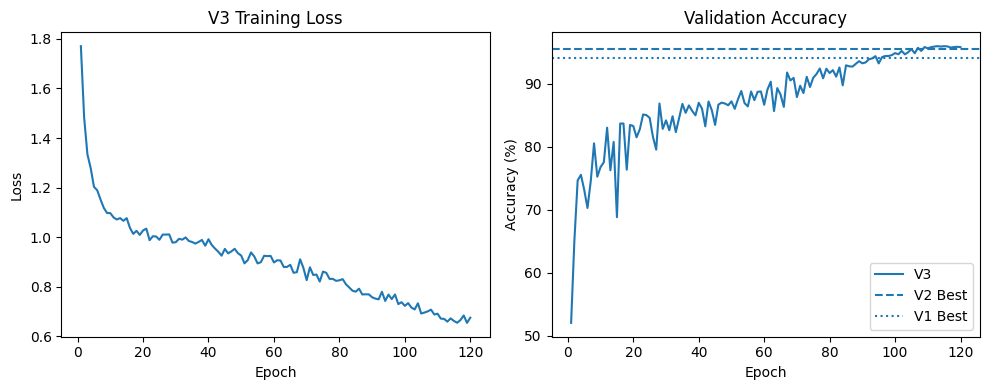

V3 best validation accuracy: 95.98%
V2 best validation accuracy: 95.56%


In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(
    range(1, len(train_losses) + 1),
    train_losses
)
plt.title("V3 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(
    range(1, len(val_accuracies) + 1),
    val_accuracies,
    label="V3"
)

plt.axhline(
    95.56,
    linestyle="--",
    label="V2 Best"
)

plt.axhline(
    94.04,
    linestyle=":",
    label="V1 Best"
)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

print(f"V3 best validation accuracy: {best_accuracy:.2f}%")
print("V2 best validation accuracy: 95.56%")

In [9]:
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            original = model(images)
            flipped = model(torch.flip(images, dims=[3]))

        probabilities = (
            torch.softmax(original.float(), dim=1)
            + torch.softmax(flipped.float(), dim=1)
        ) / 2

        predictions = probabilities.argmax(1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

tta_accuracy = 100 * correct / total

print(f"V3 validation accuracy with TTA: {tta_accuracy:.2f}%")
print("V2 best validation accuracy without TTA: 95.56%")

V3 validation accuracy with TTA: 96.32%
V2 best validation accuracy without TTA: 95.56%


In [10]:
model.eval()
predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            original = model(images)
            flipped = model(torch.flip(images, dims=[3]))

        probabilities = (
            torch.softmax(original.float(), dim=1)
            + torch.softmax(flipped.float(), dim=1)
        ) / 2

        predictions.extend(
            probabilities.argmax(1).cpu().tolist()
        )

prediction_df = test_df[["id"]].copy()
prediction_df["label"] = predictions

submission = pd.read_csv(
    project / "sample_submission.csv"
)[["id"]]

submission = submission.merge(
    prediction_df,
    on="id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == 2000
assert submission["label"].notna().all()

submission["label"] = submission["label"].astype(int)

submission.to_csv(
    project / "submission_v3.csv",
    index=False
)

print("Saved submission_v3.csv")
print(submission.head())

Saved submission_v3.csv
   id  label
0   0      6
1   1      3
2   2      3
3   3      1
4   4      3


In [13]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, 1,
                    stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        return self.relu(out + identity)


class CustomResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 48, 3, padding=1, bias=False),
            nn.BatchNorm2d(48),
            nn.ReLU(inplace=True)
        )

        self.layers = nn.Sequential(
            ResidualBlock(48, 48),
            ResidualBlock(48, 48),

            ResidualBlock(48, 96, stride=2),
            ResidualBlock(96, 96),

            ResidualBlock(96, 192, stride=2),
            ResidualBlock(192, 192),

            ResidualBlock(192, 256, stride=2),
            ResidualBlock(256, 256)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


print("CustomResNet defined successfully!")

CustomResNet defined successfully!


In [14]:
v1 = CustomResNet().to(device)
v2 = CustomResNet().to(device)
v3 = ResNetV3().to(device)

v1.load_state_dict(torch.load(
    project / "best_resnet.pth",
    map_location=device,
    weights_only=True
))

v2.load_state_dict(torch.load(
    project / "best_resnet_v2.pth",
    map_location=device,
    weights_only=True
))

v3.load_state_dict(torch.load(
    project / "best_resnet_v3.pth",
    map_location=device,
    weights_only=True
))

v1.eval()
v2.eval()
v3.eval()

print("All three models loaded!")

All three models loaded!


In [15]:
all_probs = [[], [], []]
all_labels = []

models = [v1, v2, v3]

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        flipped = torch.flip(images, dims=[3])

        for i, model in enumerate(models):
            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                original = model(images)
                flip_output = model(flipped)

            probs = (
                torch.softmax(original.float(), dim=1)
                + torch.softmax(flip_output.float(), dim=1)
            ) / 2

            all_probs[i].append(probs.cpu())

        all_labels.append(labels)

p1, p2, p3 = [
    torch.cat(probs) for probs in all_probs
]

labels = torch.cat(all_labels)

combinations = {
    "V1": p1,
    "V2": p2,
    "V3": p3,
    "V1 + V2": 0.3*p1 + 0.7*p2,
    "V2 + V3": 0.5*p2 + 0.5*p3,
    "V1 + V2 + V3": 0.15*p1 + 0.45*p2 + 0.40*p3
}

for name, probs in combinations.items():
    accuracy = (
        (probs.argmax(1) == labels).float().mean().item() * 100
    )
    print(f"{name}: {accuracy:.2f}%")

V1: 94.64%
V2: 96.20%
V3: 96.32%
V1 + V2: 96.10%
V2 + V3: 96.70%
V1 + V2 + V3: 96.66%


In [16]:
predictions = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)
        flipped = torch.flip(images, dims=[3])

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            v2_original = v2(images)
            v2_flipped = v2(flipped)

            v3_original = v3(images)
            v3_flipped = v3(flipped)

        p2 = (
            torch.softmax(v2_original.float(), dim=1)
            + torch.softmax(v2_flipped.float(), dim=1)
        ) / 2

        p3 = (
            torch.softmax(v3_original.float(), dim=1)
            + torch.softmax(v3_flipped.float(), dim=1)
        ) / 2

        combined = 0.5*p2 + 0.5*p3

        predictions.extend(
            combined.argmax(1).cpu().tolist()
        )

prediction_df = test_df[["id"]].copy()
prediction_df["label"] = predictions

submission = pd.read_csv(
    project / "sample_submission.csv"
)[["id"]]

submission = submission.merge(
    prediction_df,
    on="id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == 2000
assert submission["label"].notna().all()

submission["label"] = submission["label"].astype(int)

submission.to_csv(
    project / "submission_v2_v3.csv",
    index=False
)

print("Saved submission_v2_v3.csv")

Saved submission_v2_v3.csv
